# Прогнозирование оттока клиентов

Цель проекта - построить модель бинарной классификации, которая определяет клиентов телеком-компании с высоким риском ухода.

Целевая переменная `Churn` принимает два значения:

- `Yes` - клиент ушёл;
- `No` - клиент остался.

Такой прогноз может помочь компании заранее работать с клиентами, склонными к уходу: предлагать им более подходящие тарифы, скидки или дополнительные услуги.

В проекте выполняются первичный анализ данных, подготовка признаков, сравнение нескольких моделей, подбор регуляризации и интерпретация итогового решения.


In [1]:
import os

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")


## Загрузка данных

Используется открытый датасет Telco Customer Churn.

In [2]:
path = kagglehub.dataset_download(
    "palashfendarkar/wa-fnusec-telcocustomerchurn"
)

file_path = os.path.join(
    path,
    "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = pd.read_csv(file_path)
df.head()


100%|██████████| 172k/172k [00:00<00:00, 18.2MB/s]

Extracting files...


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Первичный анализ

Проверим размер таблицы, типы признаков, дубликаты, пропуски и распределение целевой переменной.


In [3]:
print("Размер датасета:", df.shape)
print("Количество дубликатов:", df.duplicated().sum())

print("\nОбщая информация о данных:")
df.info()

print("\nКоличество формальных пропусков:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nРаспределение целевой переменной, %:")
display(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Размер датасета: (7043, 21)
Количество дубликатов: 0

Общая информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Распределение целевой переменной, %:


,proportion
Churn,
No,73.46
Yes,26.54


In [4]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Подготовка данных

Столбец `TotalCharges` должен быть числовым, но загружен как текст из-за пустых строк. Они относятся к новым клиентам с нулевой длительностью обслуживания, поэтому после проверки заменяются на ноль.


In [5]:
empty_total_charges = df["TotalCharges"].str.strip().eq("").sum()
print("Пустых строк в TotalCharges:", empty_total_charges)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

display(
    df.loc[
        df["TotalCharges"].isnull(),
        ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
    ]
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Пропусков после обработки:", df["TotalCharges"].isnull().sum())


Пустых строк в TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Пропусков после обработки: 0


После преобразования данные не содержат пропусков. Уникальный идентификатор `customerID` будет исключён перед обучением, поскольку не несёт информации о поведении клиента.


## Исследовательский анализ

### Баланс целевой переменной


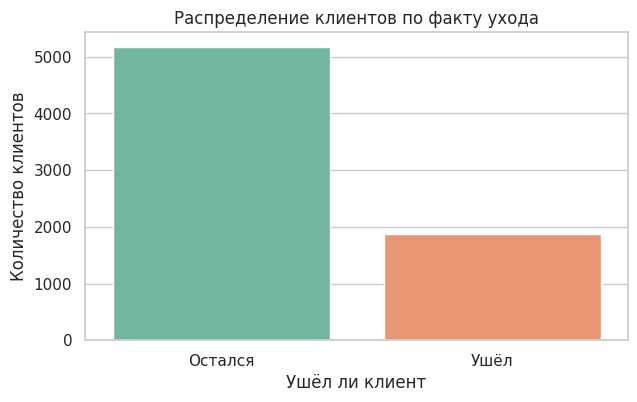

Доля ушедших клиентов: 26.5%


In [6]:
churn_rate = df["Churn"].eq("Yes").mean() * 100

plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

ax.set_title("Распределение клиентов по факту ухода")
ax.set_xlabel("Ушёл ли клиент")
ax.set_ylabel("Количество клиентов")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Остался", "Ушёл"])

plt.show()

print(f"Доля ушедших клиентов: {churn_rate:.1f}%")


Классы распределены неравномерно: 26,5% клиентов ушли, а 73,5% остались. Поэтому при оценке модели нельзя ориентироваться только на accuracy - модель, которая всегда предсказывает сохранение клиента, уже получила бы точность около 73,5%.


### Тип договора


Churn,No,Yes
Contract,,
Month-to-month,57.3,42.7
One year,88.7,11.3
Two year,97.2,2.8


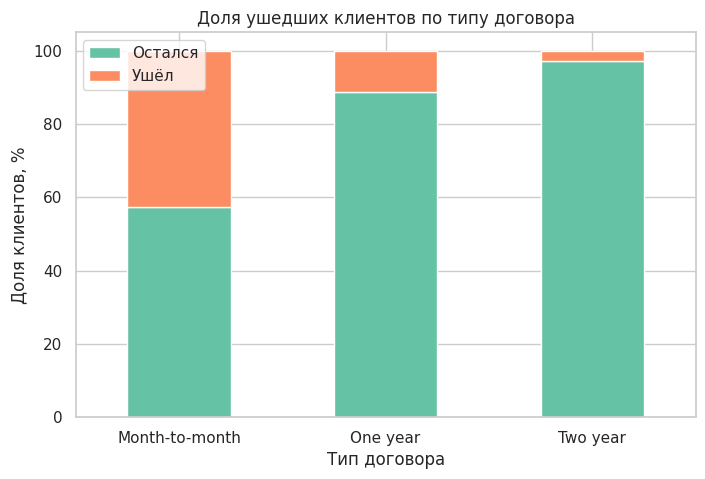

In [7]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).mul(100)

display(contract_churn.round(1))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#66c2a5", "#fc8d62"]
)

plt.title("Доля ушедших клиентов по типу договора")
plt.xlabel("Тип договора")
plt.ylabel("Доля клиентов, %")
plt.xticks(rotation=0)
plt.legend(["Остался", "Ушёл"], title="")
plt.show()


Клиенты с помесячным договором уходят заметно чаще, чем клиенты с договором на один или два года. Долгосрочный контракт связан с более низким уровнем оттока, однако сам по себе график не доказывает причинную связь.


### Длительность обслуживания и ежемесячный платёж


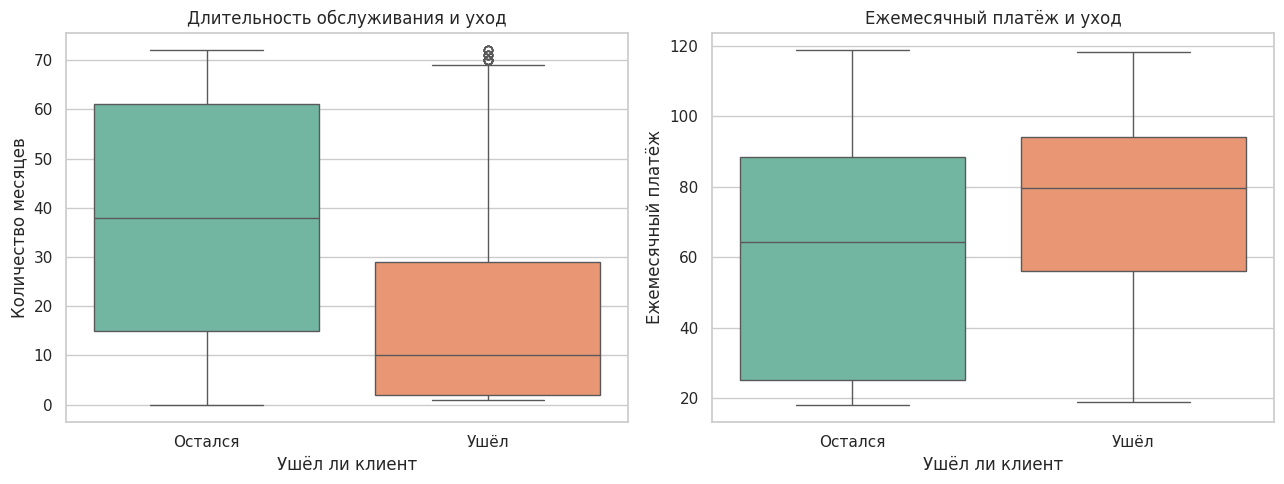

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Длительность обслуживания и уход")
axes[0].set_xlabel("Ушёл ли клиент")
axes[0].set_ylabel("Количество месяцев")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Остался", "Ушёл"])

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Ежемесячный платёж и уход")
axes[1].set_xlabel("Ушёл ли клиент")
axes[1].set_ylabel("Ежемесячный платёж")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Остался", "Ушёл"])

plt.tight_layout()
plt.show()


Ушедшие клиенты в среднем пользовались услугами меньше времени и платили больше в месяц. Первые месяцы обслуживания могут быть важным периодом для удержания клиента, а высокая стоимость услуг может быть связана с повышенным риском ухода.


## Подготовка к моделированию

Столбец `customerID` исключается из признаков. Целевая переменная преобразуется в числовой формат: `0` означает, что клиент остался, а `1` - что клиент ушёл.

Данные делятся на обучающую и тестовую выборки со стратификацией. Тестовая выборка не участвует в сравнении и настройке моделей и используется только для итоговой оценки.


In [9]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print(f"Доля ушедших в обучающей выборке: {y_train.mean():.1%}")
print(f"Доля ушедших в тестовой выборке: {y_test.mean():.1%}")


Размер обучающей выборки: (5634, 19)
Размер тестовой выборки: (1409, 19)
Доля ушедших в обучающей выборке: 26.5%
Доля ушедших в тестовой выборке: 26.5%


Числовые признаки масштабируются, а категориальные преобразуются с помощью one-hot encoding. Преобразования объединены с моделями в pipeline, чтобы они обучались только на соответствующих обучающих частях данных.

Сравниваются простая baseline-модель, обычная и сбалансированная логистическая регрессия, а также случайный лес. Основными метриками выбраны recall, F1-score, ROC-AUC и PR-AUC.


In [10]:
numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
])

logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        LogisticRegression(max_iter=1000, random_state=42)
    )
])

balanced_model = clone(logistic_model)
balanced_model.set_params(model__class_weight="balanced")

random_forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Логистическая регрессия": logistic_model,
    "Логистическая регрессия с балансировкой": balanced_model,
    "Случайный лес": random_forest_model
}


## Сравнение моделей

Для надёжного сравнения используется стратифицированная кросс-валидация из пяти частей. Доля целевого класса сохраняется в каждой части данных.


In [11]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "ROC-AUC": "roc_auc",
    "PR-AUC": "average_precision",
    "Recall": make_scorer(recall_score, zero_division=0),
    "Precision": make_scorer(precision_score, zero_division=0),
    "F1-score": make_scorer(f1_score, zero_division=0)
}

results = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Модель": model_name}

    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()

    results.append(row)

comparison = (
    pd.DataFrame(results)
    .set_index("Модель")
    .round(3)
)

display(comparison)


,ROC-AUC,PR-AUC,Recall,Precision,F1-score
Модель,,,,,
Baseline,0.500,0.265,0.000,0.000,0.000
Логистическая регрессия,0.846,0.662,0.543,0.653,0.592
Логистическая регрессия с балансировкой,0.846,0.660,0.801,0.517,0.628
Случайный лес,0.820,0.610,0.473,0.629,0.539


Лучший баланс между precision и recall показала логистическая регрессия с балансировкой классов. Она обнаруживает около 80% уходящих клиентов и получает наибольший F1-score. Случайный лес уступает обеим версиям логистической регрессии.



## Подбор регуляризации




In [12]:
regularization_search = GridSearchCV(
    estimator=clone(balanced_model),
    param_grid={
        "model__penalty": ["l1", "l2"],
        "model__C": [0.01, 0.1, 0.5, 1, 2, 10],
        "model__solver": ["liblinear"]
    },
    scoring=make_scorer(f1_score, zero_division=0),
    cv=cv,
    n_jobs=-1
)

regularization_search.fit(X_train, y_train)

print(
    "Лучшая регуляризация:",
    regularization_search.best_params_["model__penalty"]
)
print(
    "Лучшее значение C:",
    regularization_search.best_params_["model__C"]
)
print(f"Средний F1-score: {regularization_search.best_score_:.3f}")


Лучшая регуляризация: l2
Лучшее значение C: 0.1
Средний F1-score: 0.629


Подбор гиперпараметров выбирает L2-регуляризацию с `C = 0.1`. Более сильная регуляризация немного повышает F1-score и уменьшает влияние отдельных коэффициентов.


## Финальная оценка



,Значение
Accuracy,0.741
Precision,0.508
Recall,0.786
F1-score,0.617
ROC-AUC,0.841
PR-AUC,0.633


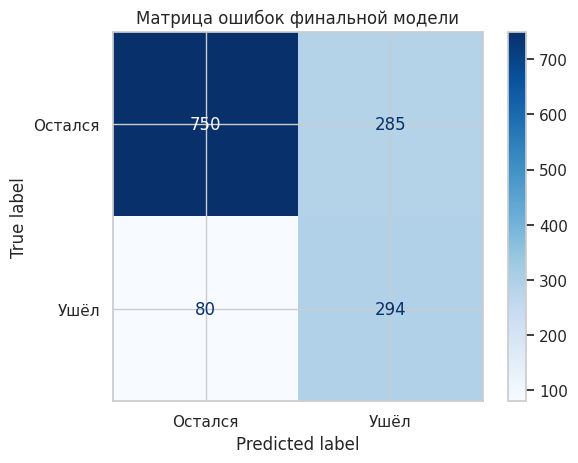

In [13]:
regularized_model = regularization_search.best_estimator_

regularized_pred = regularized_model.predict(X_test)
regularized_proba = regularized_model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, regularized_pred),
    "Precision": precision_score(y_test, regularized_pred),
    "Recall": recall_score(y_test, regularized_pred),
    "F1-score": f1_score(y_test, regularized_pred),
    "ROC-AUC": roc_auc_score(y_test, regularized_proba),
    "PR-AUC": average_precision_score(y_test, regularized_proba)
})

display(test_metrics.to_frame("Значение").round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    regularized_pred,
    display_labels=["Остался", "Ушёл"],
    cmap="Blues"
)

plt.title("Матрица ошибок финальной модели")
plt.show()


На тестовой выборке модель получила recall 0,786 и F1-score 0,617. Она обнаруживает большую часть уходящих клиентов, но часть оставшихся клиентов также попадает в группу риска. Такой результат подходит для предварительного отбора клиентов перед недорогой удерживающей коммуникацией.


## Интерпретация модели


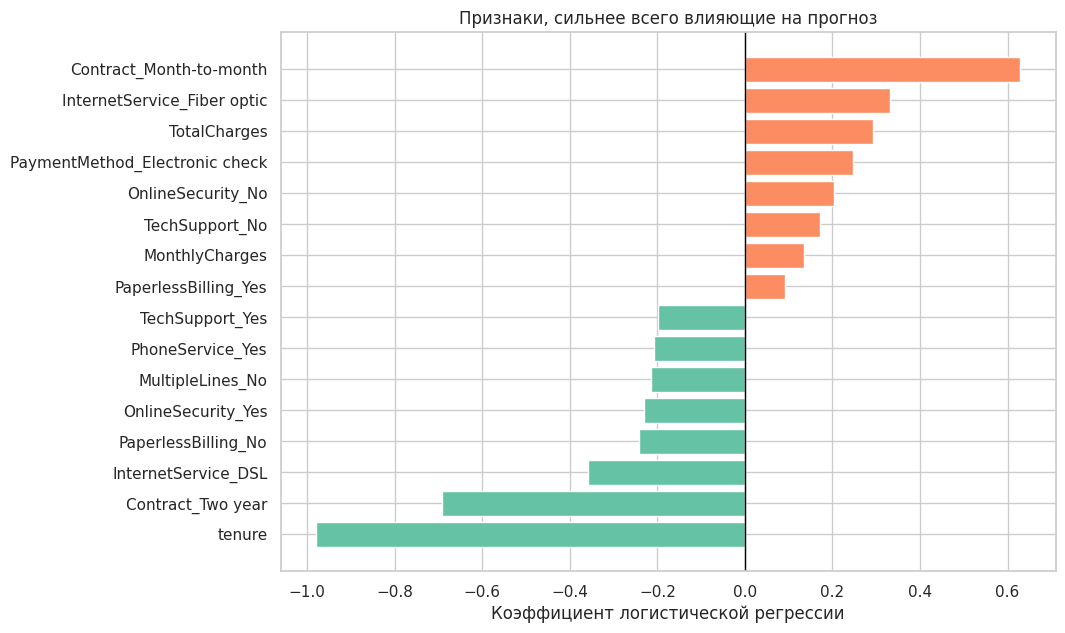

In [14]:
feature_names = (
    regularized_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_names = [
    name.split("__", 1)[-1]
    for name in feature_names
]

coefficients = (
    regularized_model
    .named_steps["model"]
    .coef_[0]
)

feature_effects = pd.DataFrame({
    "Признак": feature_names,
    "Коэффициент": coefficients
}).sort_values("Коэффициент")

important_features = pd.concat([
    feature_effects.head(8),
    feature_effects.tail(8)
])

colors = np.where(
    important_features["Коэффициент"] > 0,
    "#fc8d62",
    "#66c2a5"
)

plt.figure(figsize=(10, 7))
plt.barh(
    important_features["Признак"],
    important_features["Коэффициент"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Признаки, сильнее всего влияющие на прогноз")
plt.xlabel("Коэффициент логистической регрессии")
plt.ylabel("")
plt.show()


Наиболее заметно риск ухода повышают оптоволоконный интернет и помесячный договор. Большая длительность обслуживания и двухлетний договор, напротив, связаны с более низким прогнозируемым риском ухода.


## ROC- и Precision-Recall-кривые


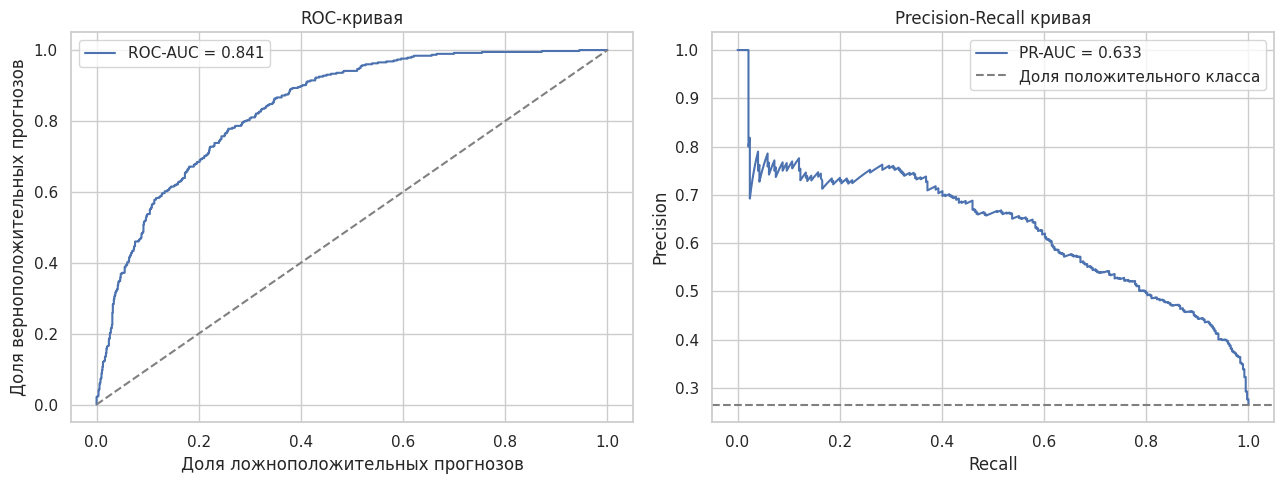

In [15]:
fpr, tpr, _ = roc_curve(y_test, regularized_proba)
precision, recall, _ = precision_recall_curve(
    y_test,
    regularized_proba
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc_score(y_test, regularized_proba):.3f}"
)
axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)
axes[0].set_title("ROC-кривая")
axes[0].set_xlabel("Доля ложноположительных прогнозов")
axes[0].set_ylabel("Доля верноположительных прогнозов")
axes[0].legend()

axes[1].plot(
    recall,
    precision,
    label=(
        "PR-AUC = "
        f"{average_precision_score(y_test, regularized_proba):.3f}"
    )
)
axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label="Доля положительного класса"
)
axes[1].set_title("Precision-Recall кривая")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()


ROC-AUC 0,841 показывает, что модель хорошо ранжирует клиентов по риску ухода. PR-AUC 0,633 значительно превышает долю положительного класса 0,265, что особенно важно при несбалансированной целевой переменной.


## Пример прогноза



In [16]:
example_customer = X_test.iloc[[0]]

churn_probability = regularized_model.predict_proba(
    example_customer
)[0, 1]
churn_prediction = regularized_model.predict(
    example_customer
)[0]

display(example_customer)

print(f"Вероятность ухода: {churn_probability:.1%}")
print(
    "Прогноз:",
    "клиент может уйти"
    if churn_prediction == 1
    else "клиент, скорее всего, останется"
)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2


Вероятность ухода: 11.1%
Прогноз: клиент, скорее всего, останется


## Итоги

В проекте построен воспроизводимый pipeline прогнозирования оттока клиентов. После сравнения моделей и подбора регуляризации выбрана логистическая регрессия с балансировкой классов и L2-регуляризацией при `C = 0.1`.

На тестовой выборке модель получила:

- ROC-AUC - 0,841;
- PR-AUC - 0,633;
- Recall - 0,786;
- Precision - 0,508;
- F1-score - 0,617.

Модель обнаруживает большую часть клиентов с риском ухода и может использоваться как инструмент предварительного отбора для удерживающих предложений.
